# Practice 3 — Directed Social Networks on Twitter/X

## Twitter interaction network: direction, influence, communities and diffusion


The practice focuses on:

- directed edges and the distinction between **in-degree** and **out-degree**;
- **reciprocity**;
- popularity/activity versus structural influence;
-  **betweenness centrality**;
- weighted interaction strength;
- strongly and weakly connected components;
- structural communities;

> **Important** A directed interaction network is not the same object as a friendship network. Direction, edge meaning and edge weight must be interpreted before any centrality score is given a social meaning.

## 1. Problem: the  U.S. Congress Twitter <font color="blue"><b>Interaction</b></font>  Network

The **U.S. Congress Twitter Interaction Network** represents activity on Twitter among members of the **United States Congress**, including members of both the **House of Representatives and the Senate**. The observation period was approximately four months, from **February 9, 2022 to June 9, 2022**.

The dataset was constructed to study Congress  as a **social and information network**. Members publish information, react to one another, reference other politicians, and potentially contribute to the propagation of information through the political communication system.


## What Twitter activity was analyzed?

- Observable interactions between congressional Twitter accounts. 
- Types of Twitter activity were considered:

| **Interaction** | **Interpretation** |
|---|---|
| **Retweet** | A member republishes another user's tweet |
| **Quote tweet** | A member republishes a tweet while adding a comment |
| **Reply** | A member directly responds to another account |
| **Mention** | A member explicitly refers to another account in a tweet |


- If Congressperson $A$ repeatedly retweets, quotes, replies to, or mentions content associated with Congressperson $B$, these observations provide evidence of a relationship between their accounts.
---

## <font color="blue"><b>Note</b></font>  that the edge has a weight.

The network is  directed and **weighted**.

Each edge has a numerical weight representing an empirically estimated **probability of transmission or influence** between the corresponding accounts.

Consequently, two edges $A \rightarrow B$ and $A \rightarrow C$ may both exist but have very different weights.

Distinguish between:

1. the **existence of an interaction relationship**, and
2. the **strength of that relationship**.

This distinction becomes particularly important when comparing **degree** and **weighted strength**.

---
## New concepts.

| **Network concept** | **Interpretation in the Twitter/X network** |
|---|---|
| **In-degree** | Number of distinct incoming interaction relationships |
| **Out-degree** | Number of distinct outgoing interaction relationships |
| **In-strength / Out-strength** | Weighted intensity of incoming or outgoing relationships |
| **Reciprocity** | Extent to which directed interactions occur in both directions |
| **Betweenness** | Potential brokerage between different regions of the network |
| **Communities** | Groups characterized by relatively dense internal interaction |

We want to explore:

> **Who interacts with whom? In which direction? How strongly? Who occupies structurally influential positions? Who connects different groups?**


## 2. Database

We use the **Twitter Interaction Network for the 117th U.S. Congress**, distributed by the Stanford Network Analysis Project (SNAP).

### Main properties

- **Nodes:** 475 Twitter accounts belonging to members of the 117th U.S. Congress.
- **Edges:** 13,289.
- **Directed:** yes.
- **Weighted:** yes.
- **Observation period:** February 9, 2022 to June 9, 2022.
- **Interactions represented:** retweets, quote tweets, replies and mentions.
- **Edge weight:** empirical probability of influence/transmission from one account to another, obtained by normalizing observed interactions.

Dataset page:

<https://snap.stanford.edu/data/congress-twitter.html>

Reference:

C. G. Fink, N. Omodt, S. Zinnecker and G. Sprint, *A Congressional Twitter network dataset quantifying pairwise probability of influence*, Data in Brief, 2023.


## 3. Imports and data load.


In [1]:
from pathlib import Path


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.patches import Patch

### 3.1 Load the directed weighted graph

The  file `congress.edgelist` is in NetworkX edge-list format. We load it as a `DiGraph`.


In [2]:

DATA_DIR = Path("congress_network")

edge_candidates = list(DATA_DIR.rglob("*.edgelist"))

edge_path = edge_candidates[0]
print("Using:", edge_path)

G = nx.read_edgelist(
    edge_path,
    create_using=nx.DiGraph(),
    nodetype=int,
    data=True
)

print(G)
print("Directed:", G.is_directed())
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

# Inspect some edges and their attributes
list(G.edges(data=True))[:5]

Using: congress_network\congress_network\congress.edgelist
DiGraph with 475 nodes and 13289 edges
Directed: True
Number of nodes: 475
Number of edges: 13289


[(0, 4, {'weight': 0.002105263157894737}),
 (0, 12, {'weight': 0.002105263157894737}),
 (0, 18, {'weight': 0.002105263157894737}),
 (0, 25, {'weight': 0.004210526315789474}),
 (0, 30, {'weight': 0.002105263157894737})]

<font color="red"><b>Python tips</b></font> 

1. Understand "DATA_DIR.rglob" command.
2. Natural format for a graph: A list of tuples. Think on a 'dict' alternative.

## 4. Exploratory data analysis

### Network Density

**Density** measures how many edges exist in a network compared with the maximum number of edges that could possibly exist.

For a directed network with $n$ nodes and $m$ directed edges, the density is $D = \frac{m}{n(n-1)}$.

- A density close to **0** indicates a **sparse network**, while a density close to **1** indicates a **highly connected network**.

Examples:

- Left: Flavour network.  Density high
- Right: Electricity network in Italy. Density Low

<div style="display: flex; justify-content: space-around; align-items: center;">
    <img src="FlavourNetwork.png" width="25%">
    <img src="PowerGridItally.png" width="25%">
</div>

### Weakly Connected Components (WCC)

A **weakly connected component** is a maximal group of nodes in a directed network that becomes connected when the **direction of the edges is ignored**.

In other words, every node in the component can be connected to every other node if we treat all directed edges as undirected.

### Strongly Connected Components (SCC)

A **strongly connected component** is a maximal group of nodes in a directed network in which **every node can reach every other node by following the direction of the edges**.

Thus, for any two nodes $u$ and $v$ in the same strongly connected component, there must be $u \rightarrow \cdots \rightarrow v$ and also $v \rightarrow \cdots \rightarrow u$.

### Reciprocity

**Reciprocity** measures the extent to which directed relationships in a network are **mutual**.

For nodes $u$ and $v$, a reciprocal relationship exists when both $u \rightarrow v$ and $v \rightarrow u$ are present.

Network reciprocity can be expressed as the proportion of directed edges for which the reverse edge also exists: $r = \frac{\text{number of edges participating in reciprocal relationships}}{\text{total number of edges}}$.

The value ranges from **0 to 1**:

- **Reciprocity = 0:** none of the directed relationships are mutual.
- **Reciprocity close to 1:** most relationships occur in both directions.

In [3]:
n = G.number_of_nodes()
m = G.number_of_edges()

summary = pd.DataFrame({
    "nodes": [n],
    "edges": [m],
    "density (%)": [nx.density(G) * 100],
    "self_loops": [nx.number_of_selfloops(G)],
    "reciprocity (%)": [nx.reciprocity(G) * 100],
    "weakly_connected_components": [nx.number_weakly_connected_components(G)],
    "strongly_connected_components": [nx.number_strongly_connected_components(G)],
})


#  Round to three decimals
summary[["density (%)", "reciprocity (%)"]] = summary[["density (%)", "reciprocity (%)"]].round(3)

display(summary.T)

,0
nodes,475.000
edges,13289.000
density (%),5.902
self_loops,0.000
reciprocity (%),46.158
weakly_connected_components,1.000
strongly_connected_components,7.000


In [6]:
# Obtain all strongly connected components
sccs = list(nx.strongly_connected_components(G))

# Create a table with the number of nodes and edges in each SCC
scc_table = pd.DataFrame([
    {
        "SCC": i + 1,
        "Nodes": len(component),
        "Edges": G.subgraph(component).number_of_edges()
    }
    for i, component in enumerate(sccs)
])

# Sort from largest to smallest SCC
scc_table = scc_table.sort_values(
    by=["Nodes", "Edges"],
    ascending=False
).reset_index(drop=True)

# Renumber SCCs according to their size
scc_table["SCC"] = range(1, len(scc_table) + 1)

scc_table

,SCC,Nodes,Edges
0,1,469,13187
1,2,1,0
2,3,1,0
3,4,1,0
4,5,1,0
5,6,1,0
6,7,1,0


## <font color="red"><b>Exercise 1</b></font>

1. Provide a short explanation of what means  that the density  is 5.9 % and that reciprocity is 46.2 %.
-  Hint: what is the meaning of the ${n(n-1)}$ component in the Density definition?, where is the "2"?
2. Explain briefly what is the meaning of the  $7$ strongly connected components found?

## <font color="green"><b>Exercise 1</b></font>

1. Que la densidad sea de 5.9% significa que no tenemos una red muy densa, que significa que de todas las conexiones que puede haber entre todos los nodos haya pocas. Por ejemplo, de tener los nodos A, B, C, D, una red muy densa sería en la que todos se conectan con todos, y una red poco densa sería por ejemplo una que conecta A con B, B con C y C con D. En este caso no se multiplica por dos devido a que las conecciones tienen dirección, por tanto las posibilidades son el doble, A puede apuntar a B pero B puede no apuntar a A.
La reciprocidad va relacionada con este segundo apartado. Aquí en lo que nos fijamos es sí de las conexiones que tenemos de un usuario a otro son "devueltas", es decir si un usuario repostea el twit de otro, si este luego repostea otro twit del primero, esto es lo que valoramos en reciprocidad.
2. Aquí lo que valoramos son los nodos que se comunican ente si por más de un camino, es decir si tenemos que A conceta con B y B con C, tenemos 3 comoponenes aisalandos a nivel de SCC, pero si C conecta con B aquí tendriamos los 3 nodos en la misma SCC, ya que se conectan entre si por más de un camino. Para decirlo de otra manera, un nodo pertenece a una SCC cuando puede volver a el por un camino distinto que el que ha usado para llegar al resto. Lo que vemos en el resultado es que hay 6 nodos que podrían estar aisalados, que a lo mejor desde otro nodo llegamos a ellos o ellos llegan a otro nodo, pero no ambas a la vez, de tal manera que no están en la red.

### 4.1 In-degree and out-degree

#### <font color="blue"><b>**Influencer only by degree of connection?**</b></font>  

For a directed interaction network:

- **out-degree** of $u$: number of distinct accounts to which $u$ sends interactions;
- **in-degree** of $u$: number of distinct accounts from which $u$ receives interactions.

Twitter vocabulary: Friends and Followers.

A high out-degree may indicate broad activity or outreach. A high in-degree may indicate visibility, attention, or being a frequent interaction target.

In [11]:
degree_df = pd.DataFrame({
    "node": list(G.nodes()),
    "in_degree": [G.in_degree(v) for v in G.nodes()],
    "out_degree": [G.out_degree(v) for v in G.nodes()],
})

degree_df["total_degree"] = degree_df["in_degree"] + degree_df["out_degree"]
print('First 10 nodes:')
display(degree_df.sort_values("out_degree", ascending=False).head(10))
print('__'*30)
print('\t Summary statistics:')
display(degree_df.describe().loc[:, ["in_degree", "out_degree", "total_degree"]].round(2))

First 10 nodes:


,node,in_degree,out_degree,total_degree
121,367,51,210,261
270,322,127,157,284
88,393,79,111,190
75,71,25,97,122
303,399,63,89,152
433,436,9,85,94
32,179,29,84,113
51,254,108,79,187
199,105,47,75,122
15,87,48,71,119


____________________________________________________________
	 Summary statistics:


,in_degree,out_degree,total_degree
count,475.00,475.00,475.00
mean,27.98,27.98,55.95
std,21.99,18.35,34.83
min,0.00,1.00,2.00
25%,13.00,17.00,33.00
50%,22.00,24.00,48.00
75%,37.00,35.00,69.00
max,127.00,210.00,284.00


## <font color="violet"><b>Homework</b></font>
Si analizamos el resultado vemos lo sigueinte, cuanto se aleja el maximo? 
- para out degree z = (max - mean)/std = (210 - 27.98)/18.35 = 9.92 sigma. Para una distribución normal este valor se encontraría lejisimos de la media, la probabilidad de obtener un valor así sería de 
$$1,7 \times 10^{-23}$$

Esto mismo lo hemos repasado en la siguiente sessión de la materia con el caso de Jose María Rato

##  Note a surprising feature:
- Max in degree/ standard deviation  -> 5.7
- Max out degree/ standard deviation -> 7.5

## Important homework:
- If this were a Gaussian phenomenon, which is the probability of these ratios?
- Compare it with the age of the universe. Since the begining of the universe (in seconds), how many times do you expect to see an event at 7 $\sigma$ from the mean?
  

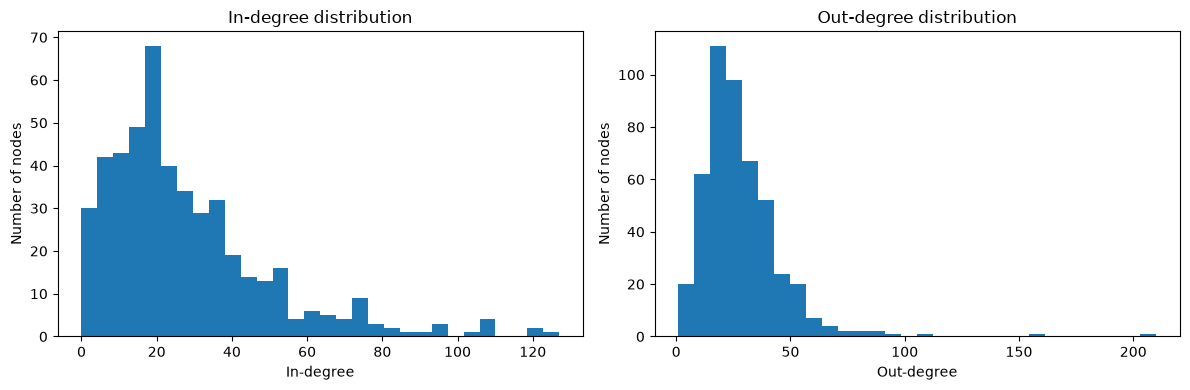

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].hist(degree_df["in_degree"], bins=30)
ax[0].set_title("In-degree distribution")
ax[0].set_xlabel("In-degree")
ax[0].set_ylabel("Number of nodes")

ax[1].hist(degree_df["out_degree"], bins=30)
ax[1].set_title("Out-degree distribution")
ax[1].set_xlabel("Out-degree")
ax[1].set_ylabel("Number of nodes")

plt.tight_layout()
plt.show()

## <font color="red"><b>Exercise 2</b></font>

The objective of this excercise is to understand both, the in/out degree distribution, and what is an asymetrical distribution.

1. Brief qualitative difference between the histograms, and the statitiscs given above.
2. Brief qualitative explanation, of why there are more outliers in the in degree vs the out degree?.
3. Brief qualitative explanation, of why should neither ranking automatically be called “influence”?

## <font color="green"><b>Exercise 2</b></font>

1. Podemos ver como ambos histogramas tienen a la mayoría de usuarios al inicio, aunque en el caso de out-degree hay outliers superiores.
2. Hay más outliers en la de out debido a que es común, la gente suele seguir a más usuarios de los que le siguen, ya que la gente suele usar las redes sociales para informarse de otros con más seguidores, al final no todo el mundo es famoso, por tanto hay menos gente que tenga un mayor inner degree.
3. Esto es debido a que tener un alto degree no the hace influenciar a los demás, lo que te hace influenciar es tener un inner degree alto, porque esto significa que mucha gente está pendiente de lo que digas y lo que hagas, y estos si que se pueden sentir influenciados. Pero tener un alto outter degree de hecho puede significar lo contrario, que te dejas influenciar mucho por lo que dicen el resto. Además, se puede dar el caso de un usuario con muchas inner conections y que los usuarios que le siguen no le hagan caso, y otro con muy pocas, pero que los 200 que le siguen le hacen siempre caso, la influencia es relativa, aunque si que tiene relación sobretodo con el inner degree.

### 4.2 Edge weights and node strength

*Remember:* **Strength** measures the **intensity of interactions** of an account by summing the weights of its connections, which represent observed Twitter interactions such as **retweets, quote tweets, replies, and mentions**.


Degree counts distinct neighbors. **Strength** uses edge weights.

For node $u$:

$
s^{out}(u)=\sum_v w_{uv},
\qquad
s^{in}(u)=\sum_v w_{vu}.
$

A node can therefore have many weak outgoing relations or a smaller number of stronger relations.

count    13289.0000
mean         0.0058
std          0.0069
min          0.0005
25%          0.0024
50%          0.0037
75%          0.0067
max          0.1306
dtype: float64

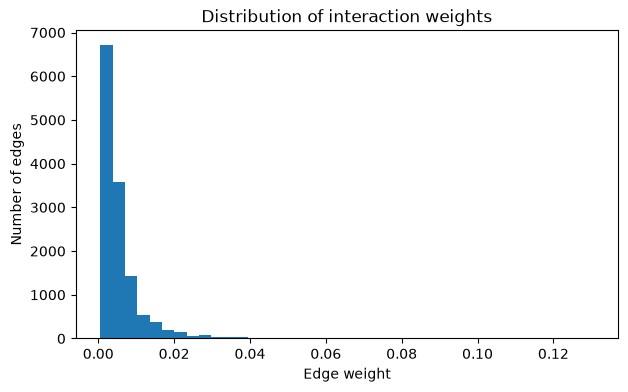

In [9]:
def edge_weight(data):
    return float(data.get("weight", 1.0))

weights = np.array([edge_weight(d) for _, _, d in G.edges(data=True)])

display(pd.Series(weights).describe().round(4))

plt.figure(figsize=(7, 4))
plt.hist(weights, bins=40)
plt.xlabel("Edge weight")
plt.ylabel("Number of edges")
plt.title("Distribution of interaction weights")
plt.show()

### Lets look into the strenght of some of the nodes.

In [10]:
# Load party information
party_names = pd.read_pickle("party_names.pkl")
# Create DataFrame with weighted in-strength and out-strength
strength_df = pd.DataFrame({
    "node": list(G.nodes()),
    "in_strength": [G.in_degree(v, weight="weight") for v in G.nodes()],
    "out_strength": [G.out_degree(v, weight="weight") for v in G.nodes()],
})

# Add username, first name, last name and party affiliation
strength_df = strength_df.merge(
    party_names[["node", "username", "first", "last", "party_name"]],
    on="node",
    how="left"
)

# Arrange columns
strength_df = strength_df[
    ["node", "username", "first", "last", "party_name",
     "in_strength", "out_strength"]
]

# Sort by out-strength
strength_df.sort_values(
    "out_strength",
    ascending=False
).head(10)

,node,username,first,last,party_name,in_strength,out_strength
121,367,SpeakerPelosi,nancy,pelosi,Democrat,0.240261,0.943639
303,399,SteveScalise,steve,scalise,Republican,0.460269,0.935115
88,393,RepBobbyRush,bobby,rush,Democrat,0.357225,0.869416
270,322,GOPLeader,kevin,mccarthy,Republican,1.648282,0.827219
59,470,RepJoeWilson,joe,wilson,Republican,0.102018,0.695238
433,436,RepMarkTakano,mark,takano,Democrat,0.025864,0.649746
412,164,RepJamesComer,james,comer,Republican,0.053671,0.603015
279,226,RepBobGood,bob,good,Republican,0.044801,0.540541
396,159,RepCloudTX,michael,cloud,Republican,0.090193,0.526316
313,208,RepFranklin,scott,franklin,Republican,0.830226,0.518325


## <font color="red"><b>Exercise 3</b></font>

Compare the top ten nodes by **out-degree** with the top ten by **out-strength**.

1. Explain if the result has sense, the most important persons of each party are Pelosi and McCarthy. What does it mean that they have different in/out strengths?
2. What does it mean to have a histogram so skewed?, note that it is not Gaussian, what kind of distribution do you think it might be?
3. Note the Max interaction vs the standard deviation?, how unlikely would it be in a Gaussian distribution (or Laplace)
   - Note: we will see the reason in the theory lecture.

## <font color="green"><b>Exercise 3</b></font>

1. Los resultados tiene sentido, la mayoría de nodos son los mismos variando el orden, cosa que tiene sentido ya que como se ha mencionado anteriormente en la prácitica, el número de nodos no es lo mismo que la fuerza de estos, puede haber nodos que vengan de 1 solo interacción y nodos que se creen a partir de centenares de interacciones, lo cual los hará más fuertes. Destacar que para el caso de Pelosi, vemos que interactua con mucha gente, pero no demasiados interactuan con el, almenos comparandolo con Mccarthy, el cual tiene un valor de in_strength y de out_strength muy grandes, significa que tiene contactos muy fuertes y esto puede proporcionar ventaja respecto al resto.
2. Significa que la mayoría de valores se ecnuentran en un pequeño rando, es decir que la mayoría de usuarios tienen un comportamiento similar, pero hay outliers gigantescos. Podría ser una distribución exponencial o una log-normal pero con outliers muy grandes.
3. Sería exageradamente extraño, pero esto es debido al Scale Free visto en teoría, que al no tener límites existen outliers gigantescos.

## 5. Reciprocity

In a directed network, a relation $u\rightarrow v$ is **reciprocated** when the reverse edge $v\rightarrow u$ also exists.

Network reciprocity is therefore a direct measure of how often directed interactions are mutual.

Twitter-like “follow” and interaction networks are particularly useful for illustrating reciprocity because one-way relations are allowed.

In [12]:
# Network reciprocity
R = nx.reciprocity(G)

print(f"Network reciprocity: {R:.4f}")

# Node reciprocity
node_recip = nx.reciprocity(G, nodes=list(G.nodes()))

# Create DataFrame with reciprocity and weighted in/out strength
node_recip_df = pd.DataFrame({
    "node": list(G.nodes()),
    "reciprocity": [node_recip[v] for v in G.nodes()],
    "in_strength": [G.in_degree(v, weight="weight") for v in G.nodes()],
    "out_strength": [G.out_degree(v, weight="weight") for v in G.nodes()]
})

# Add username, first name, last name and party affiliation
node_recip_df = node_recip_df.merge(
    party_names[["node", "username", "first", "last", "party_name"]],
    on="node",
    how="left"
)

# Arrange columns
node_recip_df = node_recip_df[
    ["node", "username", "first", "last", "party_name",
     "in_strength", "out_strength", "reciprocity"]
]

# Remove missing reciprocity values and sort by reciprocity
node_recip_df = (
    node_recip_df
    .dropna(subset=["reciprocity"])
    .sort_values("reciprocity", ascending=False)
    .reset_index(drop=True)
)

node_recip_df.head(10)

Network reciprocity: 0.4616


,node,username,first,last,party_name,in_strength,out_strength,reciprocity
0,398,RepSarbanes,john,sarbanes,Democrat,0.103824,0.122727,0.827586
1,303,RepAndyLevin,andy,levin,Democrat,0.632702,0.120654,0.736196
2,322,GOPLeader,kevin,mccarthy,Republican,1.648282,0.827219,0.725352
3,426,RepPeteStauber,pete,stauber,Republican,0.178351,0.192440,0.723404
4,55,SenJeffMerkley,jeff,merkley,Democrat,0.409429,0.115584,0.707317
5,7,JohnBoozman,john,boozman,Republican,0.183854,0.097152,0.703704
6,427,RepSteel,michelle,steel,Republican,0.174723,0.117166,0.703704
7,376,RepPressley,Ayanna,Pressley,Democrat,0.349030,0.202465,0.703297
8,318,RepThomasMassie,thomas,massie,Republican,0.526901,0.147783,0.702128
9,263,RepJayapal,pramila,jayapal,Democrat,0.471149,0.156794,0.700000


## <font color="red"><b>Exercise 4</b></font>

1. Explain the difference the fact that the nodes with the highest reciprocity index, do not correspon to the nodes with more strength. What do you think is the function of these high reciprocal nodes?


## <font color="green"><b>Exercise 4</b></font>

1. La reprocidad mide cuando una relacion entre nodos es mutua, esto no tiene porque repetirse muchas veces, por tanto no es necesario tener un valor de strength alto, miden cosas distintas. La funcion de estos nodos posiblemente sea favorecer la cohesion de una comunidad, la confianza y facilitar el intercambio de información, ya que las interacciones que hacen son mutuas se puede presuponer una relación.

## 6. Weak and strong connectivity

Direction introduces two different notions of connectedness.

- A **weakly connected component (WCC)** is connected after edge directions are ignored.
- A **strongly connected component (SCC)** requires directed paths in both directions between every pair of nodes in the component.

A large WCC together with a much smaller SCC is common in directed information-flow networks.

In [13]:
wccs = sorted(nx.weakly_connected_components(G), key=len, reverse=True)
sccs = sorted(nx.strongly_connected_components(G), key=len, reverse=True)

print("Largest WCC:", len(wccs[0]))
print("Largest SCC:", len(sccs[0]))
print("Fraction in largest WCC:", len(wccs[0]) / n)
print("Fraction in largest SCC:", len(sccs[0]) / n)

Largest WCC: 475
Largest SCC: 469
Fraction in largest WCC: 1.0
Fraction in largest SCC: 0.9873684210526316


###  **Important Note**: The existence of connected component will be important in  future lessons, so remember this issue.

## <font color="red"><b>Exercise 5</b></font>
Answer briefly

1. Why is the largest strongly connected component generally no larger than the largest weakly connected component?

2. What does a large SCC mean in terms of potential directed reachability?
3. What does it mean that the strong and weak connected components are almost equal?. See statitics in a previous section.

## <font color="green"><b>Exercise 5</b></font>

1. Porque forzosamente, por definición, una SCC siempre será tambíen una WCC, pero no al revés, ya que se puede dar el caso de que debido a las direcciones, en algún momento se corte la SCC.
2. Significa que la posibilidad de llegar de un nodo a otro siguiendo las aritstas es altamente probable.
3. Que los nodos están bastante conectados teniendo en cuenta las direcciones, es decir que en este mismo grupo de conexiones de nodo, casi todos los nodos están conectados entre sí por al menos ambos sentidos, por esto el valor de SSC se acerca tanto al de WCC.

## 7. Visualizing the complete directed network

Drawing all 475 nodes and 13,289 edges can obscure rather than reveal structure. We therefore construct a **structural sample**: the nodes with the largest total weighted strength.

This is a visualization choice, not a statistical sample of the population.

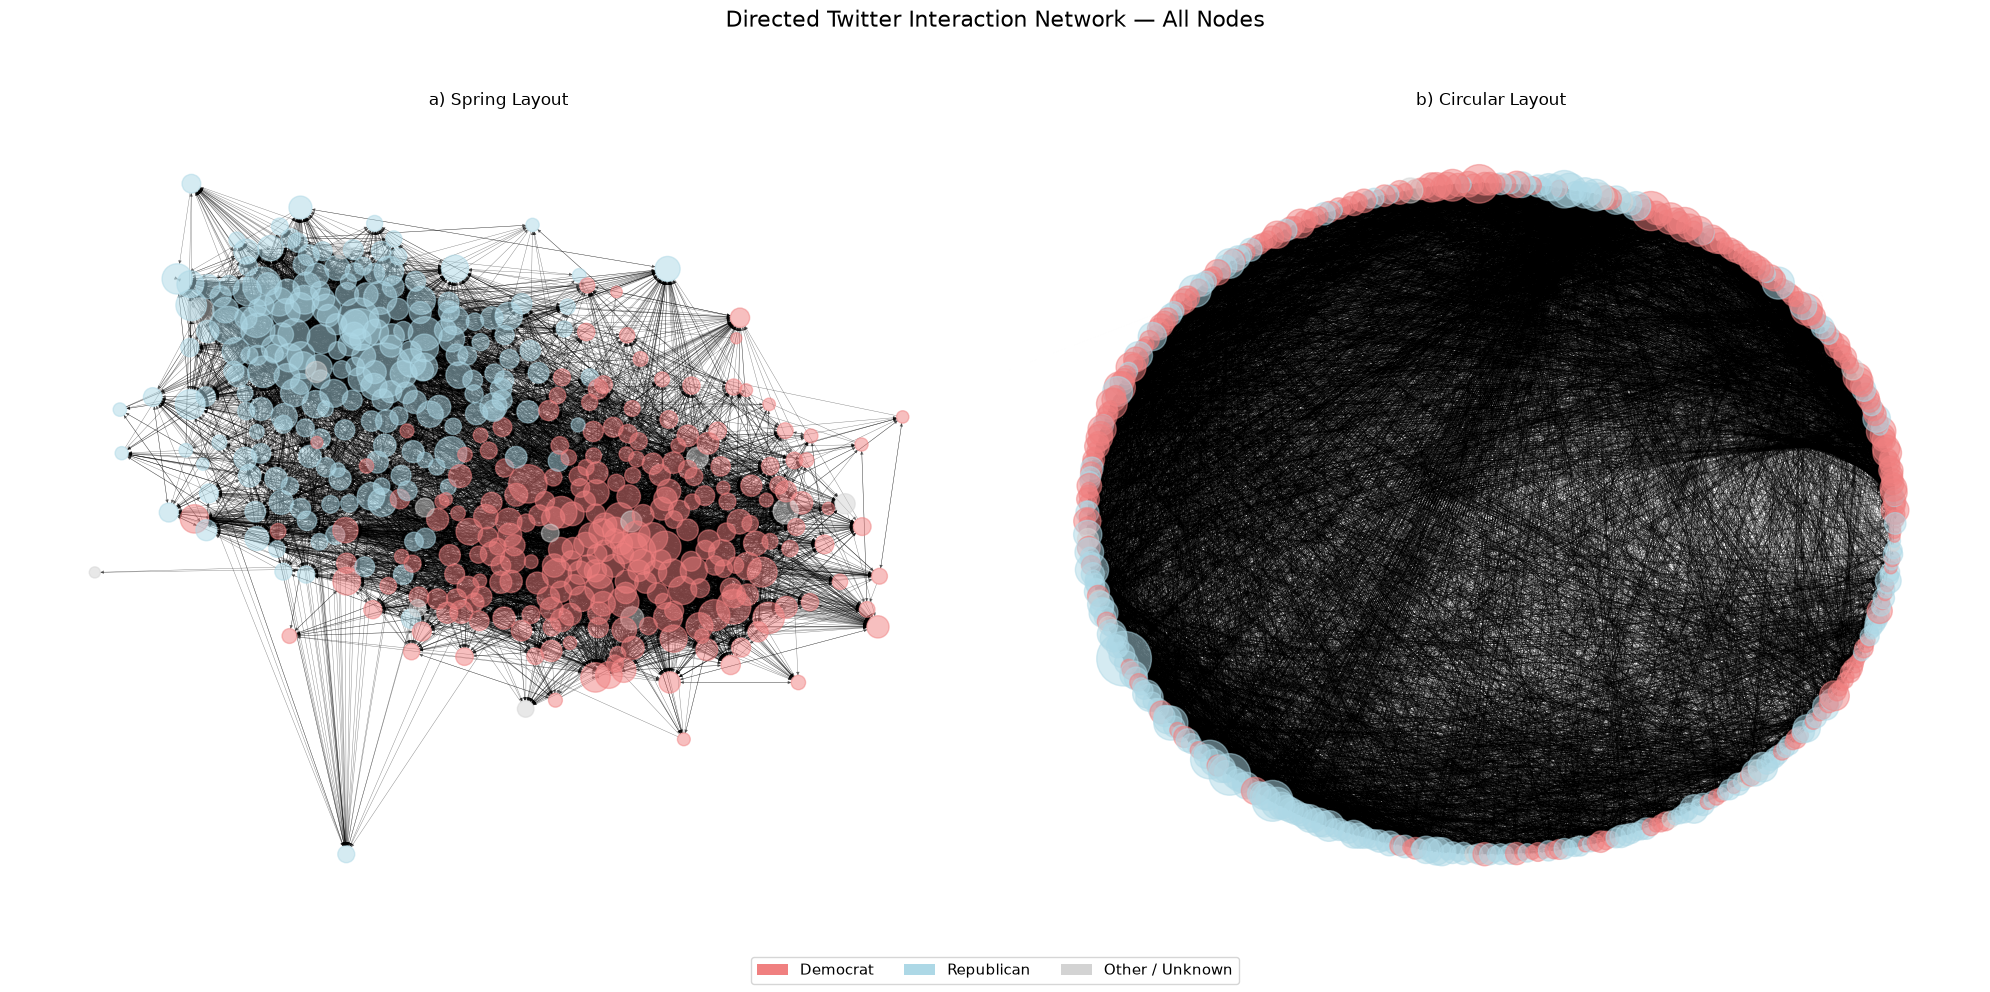

In [14]:


# Load party information
party_names = pd.read_pickle("party_names.pkl")

# Create dictionary: node -> party_name
party_dict = party_names.set_index("node")["party_name"].to_dict()

# Assign colors according to political party
node_colors = [
    "lightcoral" if party_dict.get(v) == "Democrat"
    else "lightblue" if party_dict.get(v) == "Republican"
    else "lightgray"
    for v in G.nodes()
]

# Total weighted strength of each node
strength_total = {
    v: G.in_degree(v, weight="weight") + G.out_degree(v, weight="weight")
    for v in G.nodes()
}

# Scale node sizes according to weighted strength
max_strength = max(strength_total.values())

node_sizes = [
    50 + 1500 * strength_total[v] / max_strength
    for v in G.nodes()
]

# Create the two layouts
pos_spring = nx.spring_layout(G, seed=42, weight="weight")
pos_circular = nx.circular_layout(G)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(20, 10))

# a) Spring layout
nx.draw_networkx(
    G, pos=pos_spring, ax=axes[0], with_labels=False,
    node_size=node_sizes, node_color=node_colors,
    width=0.3, arrows=True, arrowsize=5, alpha=0.5
)

axes[0].set_title("a) Spring Layout")
axes[0].axis("off")

# b) Circular layout
nx.draw_networkx(
    G, pos=pos_circular, ax=axes[1], with_labels=False,
    node_size=node_sizes, node_color=node_colors,
    width=0.3, arrows=True, arrowsize=5, alpha=0.5
)

axes[1].set_title("b) Circular Layout")
axes[1].axis("off")

# Legend
legend_elements = [
    Patch(facecolor="lightcoral", label="Democrat"),
    Patch(facecolor="lightblue", label="Republican"),
    Patch(facecolor="lightgray", label="Other / Unknown")
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=3,
    fontsize=11
)

plt.suptitle(
    "Directed Twitter Interaction Network — All Nodes",
    fontsize=16
)

plt.tight_layout(rect=[0, 0.05, 1, 0.95])
plt.show()

#### Plot only the top **50** nodes sorted by weight.
- Extract a more interpretable high-strength core from the much larger network.
- Node size proportional to strength

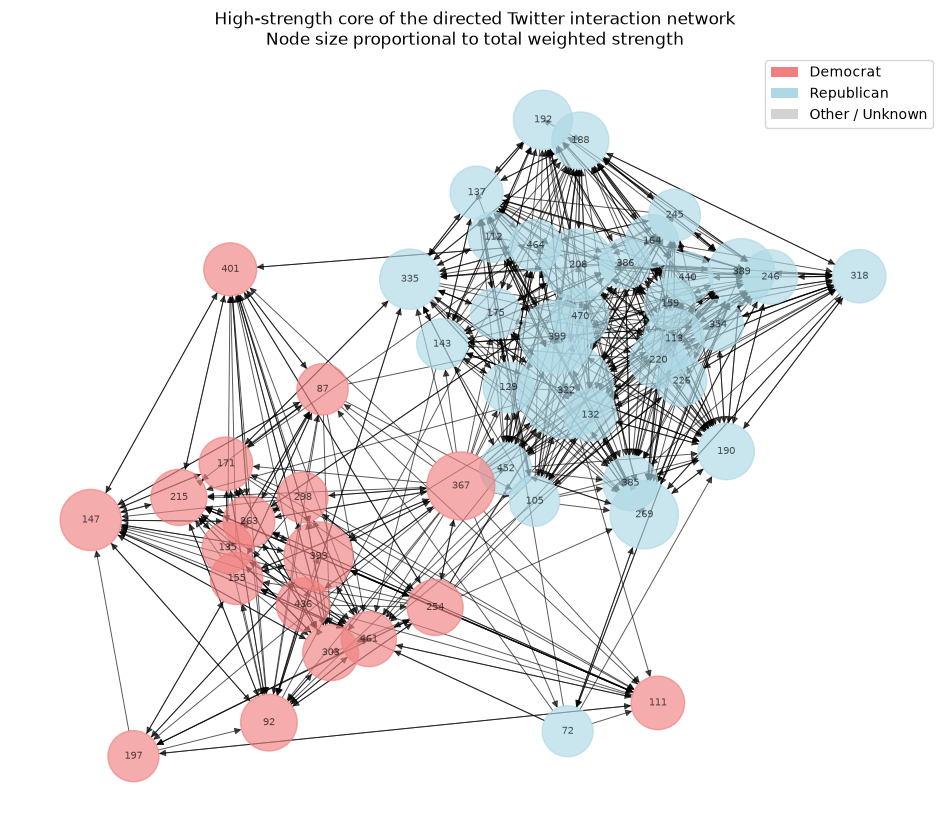

In [15]:


# Create dictionary: node -> party_name
party_dict = party_names.set_index("node")["party_name"].to_dict()

# Total weighted strength of each node
strength_total = {
    v: G.in_degree(v, weight="weight") + G.out_degree(v, weight="weight")
    for v in G.nodes()
}

# Select the 50 nodes with highest total weighted strength
top_nodes = sorted(
    strength_total,
    key=strength_total.get,
    reverse=True
)[:50]

# Create induced subgraph
H = G.subgraph(top_nodes).copy()

# Layout
plt.figure(figsize=(12, 10))

pos = nx.spring_layout(H, seed=42, weight="weight")

# Node size proportional to total weighted strength
node_sizes = [
    250 + 4500 * strength_total[v] / max(strength_total.values())
    for v in H.nodes()
]

# Node color according to political party
node_colors = [
    "lightcoral" if party_dict.get(v) == "Democrat"
    else "lightblue" if party_dict.get(v) == "Republican"
    else "lightgray"
    for v in H.nodes()
]

# Draw network
nx.draw_networkx(
    H, pos=pos, with_labels=True,
    node_size=node_sizes,
    node_color=node_colors,
    font_size=7,
    width=0.7,
    arrows=True,
    arrowsize=10,
    alpha=0.65
)

# Legend
legend_elements = [
    Patch(facecolor="lightcoral", label="Democrat"),
    Patch(facecolor="lightblue", label="Republican"),
    Patch(facecolor="lightgray", label="Other / Unknown")
]

plt.legend(handles=legend_elements, loc="upper right")

plt.title(
    "High-strength core of the directed Twitter interaction network\n"
    "Node size proportional to total weighted strength"
)

plt.axis("off")
plt.show()

## <font color="red"><b>Exercise 6</b></font>
Answer briefly

1. Pros and cons of using the complete graph vs a subset.
2. Justify from the histogram related to the strengths why it has sense to select a subset of nodes using strength as criterion. Who are the users that are droped down.
3. What can you say from user 367?, compare with user 147 and user 318.
4. Provide a common sense method for detecting communities.

## <font color="green"><b>Exercise 5</b></font>

1. Cuando usamos el gráifoc completo podemos ver las dimensiones de las que hablamos y no perdemos información, el problema es que no se entiende nada. La ventaja del subset es que se puede extraer información y entender mejor a simple vista, la desventaja, que estamos obviando muchos nodos que pueden ser importantes e influenciar.
2. Tiene sentido usar la strength porque nos centramos en las relaciones que más se dan, en los nodos que más interactuan, porque como hemos dicho, el degree indica contactos, pero la strength indica la el número de veces que se realizan las interacciones.
3. Podemos ver que el usuario 367 además de tener mucha fuerza, igual que los otros dos, las interacciones no solo las tiene con su partido, sino que se comunica con ambos, teniendo una posición muy ventajosa respecto al resto al poder obtener información y confianza de ambos lados, los otros tiene mucha fuerza pero aparentemente solo de su partido. El 367 tendrá un alto valor de betweeness centrality.
4. Podríamos aplicar clustering, calcular el clustering coefficient.

### Lets see how it behaves with the reciprocity

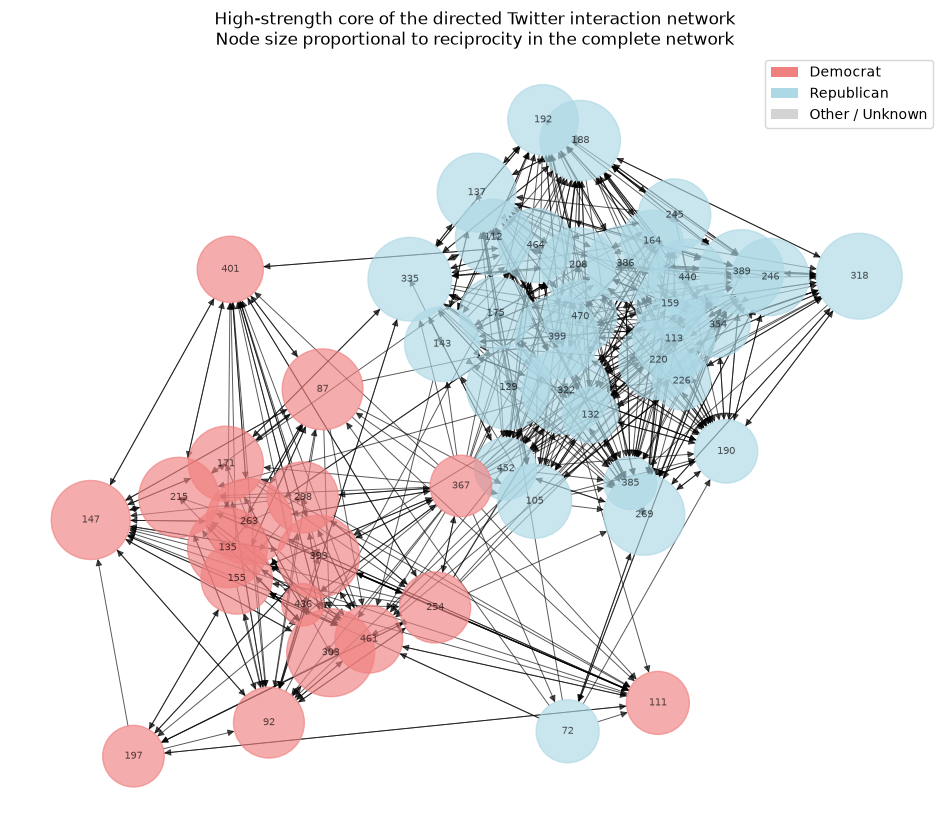

In [16]:
from matplotlib.patches import Patch

# Create dictionary: node -> party_name
party_dict = party_names.set_index("node")["party_name"].to_dict()

# Node reciprocity computed on the COMPLETE graph
node_recip = nx.reciprocity(G, nodes=list(G.nodes()))

# Replace undefined reciprocity values (None) by 0
node_recip = {
    v: 0 if node_recip[v] is None else node_recip[v]
    for v in G.nodes()
}

# Total weighted strength
strength_total = {
    v: G.in_degree(v, weight="weight") + G.out_degree(v, weight="weight")
    for v in G.nodes()
}

# Select the 50 nodes with highest total strength
top_nodes = sorted(
    strength_total,
    key=strength_total.get,
    reverse=True
)[:50]

# Create induced subgraph
H = G.subgraph(top_nodes).copy()

# Layout
plt.figure(figsize=(12, 10))

pos = nx.spring_layout(H, seed=42, weight="weight")

# Node size proportional to reciprocity computed on the COMPLETE graph
max_recip = max(node_recip.values())

node_sizes = [
    1 + 4500 * node_recip[v] / max_recip
    for v in H.nodes()
]

# Node color according to political party
node_colors = [
    "lightcoral" if party_dict.get(v) == "Democrat"
    else "lightblue" if party_dict.get(v) == "Republican"
    else "lightgray"
    for v in H.nodes()
]

# Draw network
nx.draw_networkx(
    H, pos=pos, with_labels=True,
    node_size=node_sizes,
    node_color=node_colors,
    font_size=7,
    width=0.7,
    arrows=True,
    arrowsize=10,
    alpha=0.65
)

# Legend
legend_elements = [
    Patch(facecolor="lightcoral", label="Democrat"),
    Patch(facecolor="lightblue", label="Republican"),
    Patch(facecolor="lightgray", label="Other / Unknown")
]

plt.legend(handles=legend_elements, loc="upper right")

plt.title(
    "High-strength core of the directed Twitter interaction network\n"
    "Node size proportional to reciprocity in the complete network"
)

plt.axis("off")
plt.show()

In [17]:
# Create table with node metrics and party information
node_metrics = pd.DataFrame({
    "Node": list(G.nodes()),
    "strength": [strength_total[v] for v in G.nodes()],
    "reciprocity": [node_recip[v] for v in G.nodes()]
})

# Add username, first name, last name and party_name
node_metrics = node_metrics.merge(
    party_names[["node", "username", "first", "last", "party_name"]],
    left_on="Node",
    right_on="node",
    how="left"
)

# Arrange columns
node_metrics = node_metrics[
    ["Node", "username", "first", "last", "party_name", "strength", "reciprocity"]
]

# -------------------------------------------------------
# Table sorted by strength
# -------------------------------------------------------

node_metrics_strength = (
    node_metrics
    .sort_values("strength", ascending=False)
    .reset_index(drop=True)
)

print("Nodes sorted by total weighted strength:")
display(node_metrics_strength.round(2).head(10).T)


# -------------------------------------------------------
# Table sorted by reciprocity
# -------------------------------------------------------

node_metrics_reciprocity = (
    node_metrics
    .sort_values("reciprocity", ascending=False)
    .reset_index(drop=True)
)

print("Nodes sorted by reciprocity:")
display(node_metrics_reciprocity.round(2).head(10).T)

Nodes sorted by total weighted strength:


,0,1,2,3,4,5,6,7,8,9
Node,322,399,208,393,269,367,389,147,113,335
username,GOPLeader,SteveScalise,RepFranklin,RepBobbyRush,RepMikeJohnson,SpeakerPelosi,RepChipRoy,RepCasten,RepAndyBiggsAZ,RepMMM
first,kevin,steve,scott,bobby,mike,nancy,chip,sean,andy,mariannette
last,mccarthy,scalise,franklin,rush,johnson,pelosi,roy,casten,biggs,miller-meeks
party_name,Republican,Republican,Republican,Democrat,Republican,Democrat,Republican,Democrat,Republican,Republican
strength,2.48,1.4,1.35,1.23,1.2,1.18,1.12,0.93,0.91,0.9
reciprocity,0.73,0.66,0.53,0.64,0.63,0.36,0.68,0.59,0.63,0.67


Nodes sorted by reciprocity:


,0,1,2,3,4,5,6,7,8,9
Node,398,303,322,426,55,7,427,376,318,263
username,RepSarbanes,RepAndyLevin,GOPLeader,RepPeteStauber,SenJeffMerkley,JohnBoozman,RepSteel,RepPressley,RepThomasMassie,RepJayapal
first,john,andy,kevin,pete,jeff,john,michelle,Ayanna,thomas,pramila
last,sarbanes,levin,mccarthy,stauber,merkley,boozman,steel,Pressley,massie,jayapal
party_name,Democrat,Democrat,Republican,Republican,Democrat,Republican,Republican,Democrat,Republican,Democrat
strength,0.23,0.75,2.48,0.37,0.53,0.28,0.29,0.55,0.67,0.63
reciprocity,0.83,0.74,0.73,0.72,0.71,0.7,0.7,0.7,0.7,0.7


## Interpretation of Strength and Reciprocity Rankings

### 1. Weighted Strength

For a directed weighted network, the **total strength** of node $i$ is $s_i=s_i^{in}+s_i^{out}$, where $s_i^{in}=\sum_j w_{ji}$ and $s_i^{out}=\sum_j w_{ij}$.

Strength therefore measures the **total intensity of the weighted interactions** associated with an account.

### Top 3 by Weighted Strength

| Rank | Representative | Party | Strength | Interpretation |
|---|---|---|---:|---|
| 1 | **Kevin McCarthy** | Republican | **2.48** | McCarthy was House Minority Leader during the 117th Congress. His leadership position is consistent with his exceptionally high level of weighted interaction. |
| 2 | **Steve Scalise** | Republican | **1.40** | Scalise was Republican Whip. His role coordinating Republican representatives provides a plausible context for his high interaction strength. |
| 3 | **Scott Franklin** | Republican | **1.35** | Franklin was a Republican representative from Florida. His high ranking indicates unusually strong Twitter interaction, despite not holding a top House leadership position. |

The results show that **high strength can be associated with political prominence**, particularly for McCarthy and Scalise, but strength itself measures network interaction rather than political power.

---

### 2. Reciprocity

**Node reciprocity** measures the proportion of a node's directed relationships that are mutual. It can be expressed as $r_i=L_i^{\leftrightarrow}/L_i$, where $L_i$ is the number of directed edges involving node $i$ and $L_i^{\leftrightarrow}$ represents those belonging to reciprocated relationships.

A value close to $1$ indicates highly **bidirectional interaction**, while a value close to $0$ indicates predominantly **one-way interaction**.

### Top 3 by Reciprocity

| Rank | Representative | Party | Reciprocity | Interpretation |  
|---|---|---|---:|---|
| 1 | **John Sarbanes** | Democrat | **0.83** | Sarbanes has the most reciprocal interaction pattern. However, his low strength (0.23) shows that high mutuality does not imply high interaction intensity. |
| 2 | **Andy Levin** | Democrat | **0.74** | Levin's interactions are strongly bidirectional, although his overall interaction strength is considerably lower than the highest-strength accounts. |
| 3 | **Kevin McCarthy** | Republican | **0.73** | McCarthy is notable because he combines very high reciprocity with the **highest strength (2.48)** in the network. |

### Main Result

The two measures capture different network properties:

- **Strength:** *How intense are the account's weighted interactions?*
- **Reciprocity:** *How mutual are the account's directed relationships?*

**Kevin McCarthy is particularly notable:** he ranks **1st in strength** and **3rd in reciprocity**, combining high interaction intensity with high interaction mutuality. In contrast, **John Sarbanes** ranks 1st in reciprocity but has low strength, demonstrating that an account can have highly reciprocal relationships without having a large overall interaction intensity.

# <font color="red"><b>Exercise 7</b></font>

1. Explain briefly what complementary information is provided by reprocity and by strength, relate this to the functions of the nodes in the network and problem at hand.
2. Explain the different cultures of political parties, why one dominates in the axis of strength and the other on the axis of reciprocity.

# <font color="green"><b>Exercise 7</b></font>

1. Vemos que el partido republicano tiene gran fuerza, significando que tiene más interacciones que el partido democrata, por el lado contrario vemos que el partido deomcrata tiene más relaciones mutuas, sugiriendo que existen mayores relaciones.
2. El partido republicano parece que seguía una política de mayor propaganda teniendo más interacciones, les importaba más la visibilidad. En cambio el aprtido democrata sigue una cultura mayor de mutuo acuerdo entre miembros de partido y no tanta propaganda.

## 8. Centrality: popularity, brokerage and structural influence

No single centrality measure is “the” measure of importance.

We compare:

- **in-degree**: how many distinct nodes send interactions to the account;
- **out-degree**: how many distinct nodes receive interactions from the account;
- **betweenness centrality**: brokerage on shortest paths.

The key task is not merely calculating the values but explaining what structural mechanism each metric captures.

### Betweenness Centrality

**Betweenness centrality** measures **brokerage**: how often a node acts as an intermediary on the shortest paths connecting other nodes in the network.

For a node $v$, betweenness centrality is defined as $C_B(v)=\sum_{s \neq v \neq t}\frac{\sigma_{st}(v)}{\sigma_{st}}$.

In this expression:

- $\sigma_{st}$ is the **total number of shortest paths** connecting source node $s$ to target node $t$.
- $\sigma_{st}(v)$ is the **number of those shortest paths that pass through node $v$**.
- Therefore, the ratio $\frac{\sigma_{st}(v)}{\sigma_{st}}$ represents the **fraction of shortest paths from $s$ to $t$ that depend on node $v$**.

A node has **high betweenness** when many shortest paths between other accounts pass through it. Such a node can therefore act as a **bridge or broker** connecting different parts of the network.

Because the edge `weight` in this network represents a **transmission probability**, it should **not** be used directly as a path distance. A larger probability represents a stronger interaction, whereas a shortest-path algorithm interprets a larger weight as a larger cost or distance.


In [18]:
# Betweenness centrality on the complete network
betweenness = nx.betweenness_centrality(
    G,
    normalized=True,
    weight=None
)

# Create DataFrame with betweenness and weighted in/out strength
btw_df = pd.DataFrame({
    "node": list(G.nodes()),
    "betweenness": [betweenness[v] for v in G.nodes()],
    "in_strength": [G.in_degree(v, weight="weight") for v in G.nodes()],
    "out_strength": [G.out_degree(v, weight="weight") for v in G.nodes()]
})

# Add username, first name, last name and party affiliation
btw_df = btw_df.merge(
    party_names[["node", "username", "first", "last", "party_name"]],
    on="node",
    how="left"
)

# Arrange columns
btw_df = btw_df[
    ["node", "username", "first", "last", "party_name",
     "in_strength", "out_strength", "betweenness"]
]

# Sort by betweenness
btw_df = (
    btw_df
    .sort_values("betweenness", ascending=False)
    .reset_index(drop=True)
)

btw_df.head(10)

,node,username,first,last,party_name,in_strength,out_strength,betweenness
0,322,GOPLeader,kevin,mccarthy,Republican,1.648282,0.827219,0.073041
1,367,SpeakerPelosi,nancy,pelosi,Democrat,0.240261,0.943639,0.041412
2,254,LeaderHoyer,steny,hoyer,Democrat,0.524778,0.233333,0.030683
3,393,RepBobbyRush,bobby,rush,Democrat,0.357225,0.869416,0.027178
4,335,RepMMM,mariannette,miller-meeks,Republican,0.728135,0.169841,0.017753
5,208,RepFranklin,scott,franklin,Republican,0.830226,0.518325,0.016860
6,17,JohnCornyn,john,cornyn,Republican,0.506804,0.058916,0.016459
7,303,RepAndyLevin,andy,levin,Democrat,0.632702,0.120654,0.015542
8,461,RepBonnie,bonnie,watsoncoleman,Democrat,0.508192,0.216612,0.014342
9,113,RepAndyBiggsAZ,andy,biggs,Republican,0.638543,0.271186,0.012722


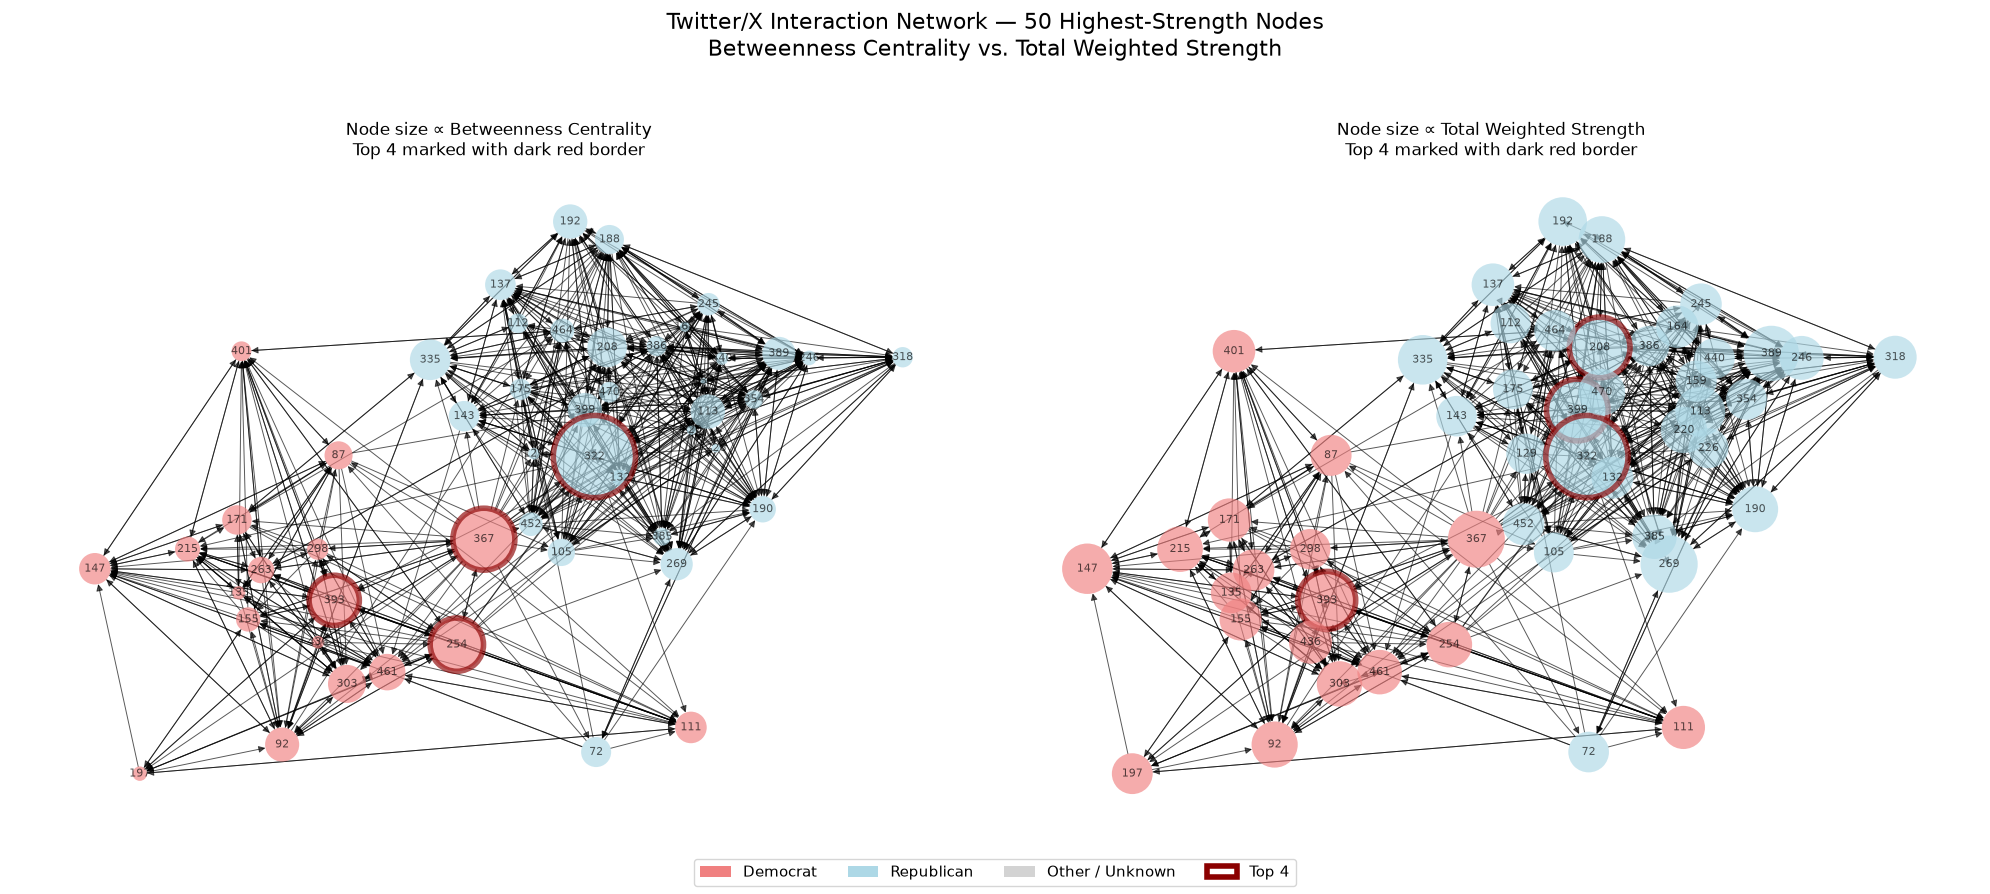

In [19]:
from matplotlib.patches import Patch

N = 50

# Party, strength and betweenness
party_dict = party_names.set_index("node")["party_name"].to_dict()
strength_total = {v: G.in_degree(v, weight="weight") + G.out_degree(v, weight="weight") for v in G.nodes()}
betweenness = nx.betweenness_centrality(G, normalized=True, weight=None)

# Select the N highest-strength nodes
top_nodes = sorted(strength_total, key=strength_total.get, reverse=True)[:N]
H = G.subgraph(top_nodes).copy()

# Top 4 nodes
top4_betweenness = set(sorted(H.nodes(), key=lambda v: betweenness[v], reverse=True)[:4])
top4_strength = set(sorted(H.nodes(), key=lambda v: strength_total[v], reverse=True)[:4])

# Layout
pos = nx.spring_layout(H, seed=42, weight="weight")

# Node sizes
sizes_betweenness = [5 + 3500 * betweenness[v] / max(betweenness.values()) for v in H.nodes()]
sizes_strength = [5 + 3500 * strength_total[v] / max(strength_total.values()) for v in H.nodes()]

# Party colors
node_colors = ["lightcoral" if party_dict.get(v) == "Democrat" else "lightblue" if party_dict.get(v) == "Republican" else "lightgray" for v in H.nodes()]

# Dark-red borders for top 4
edgecolors_betweenness = ["darkred" if v in top4_betweenness else "none" for v in H.nodes()]
linewidths_betweenness = [4 if v in top4_betweenness else 0 for v in H.nodes()]

edgecolors_strength = ["darkred" if v in top4_strength else "none" for v in H.nodes()]
linewidths_strength = [4 if v in top4_strength else 0 for v in H.nodes()]

# Side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(20, 9))

nx.draw_networkx(H, pos=pos, ax=axes[0], with_labels=True, node_size=sizes_betweenness, node_color=node_colors, edgecolors=edgecolors_betweenness, linewidths=linewidths_betweenness, font_size=8, width=0.7, arrows=True, arrowsize=10, alpha=0.65)
axes[0].set_title("Node size ∝ Betweenness Centrality\nTop 4 marked with dark red border")
axes[0].axis("off")

nx.draw_networkx(H, pos=pos, ax=axes[1], with_labels=True, node_size=sizes_strength, node_color=node_colors, edgecolors=edgecolors_strength, linewidths=linewidths_strength, font_size=8, width=0.7, arrows=True, arrowsize=10, alpha=0.65)
axes[1].set_title("Node size ∝ Total Weighted Strength\nTop 4 marked with dark red border")
axes[1].axis("off")

# Legend
legend_elements = [Patch(facecolor="lightcoral", label="Democrat"), Patch(facecolor="lightblue", label="Republican"), Patch(facecolor="lightgray", label="Other / Unknown"), Patch(facecolor="white", edgecolor="darkred", linewidth=4, label="Top 4")]

fig.legend(handles=legend_elements, loc="lower center", ncol=4, fontsize=11)
fig.suptitle(f"Twitter/X Interaction Network — {N} Highest-Strength Nodes\nBetweenness Centrality vs. Total Weighted Strength", fontsize=16)

plt.tight_layout(rect=[0, 0.05, 1, 0.95])
plt.show()

# <font color="red"><b>Exercise 8</b></font>

1. Explain briefly what can you say from the location of Pelosi and McCarthy in boths graphs?.
2. Note the different distribution by political party of the top betweeness and weighted streghth. What can you say about the different approaches to the network that characterizes each political party?

# <font color="green"><b>Exercise 8</b></font>

1. Como ya habiamos imaginado en apartados anteriores, tienen un alto valor de betweeness centrality, es decir son un gran nodo de conexion entre partidos y en un mismo partido. Cabe destacar que McCarthy tiene mayor fuerza, posiblemente debido a que forma parte del partido republicano, el cual hemos asumido que se enfocaba más en la propaganada.
2. Como hemos supuesto en apartados anteriores el partido republicano tiene menos fuerza pero más conexiones de peso o importantes, por esto tiene nodos con mayor betweeness centrality, en cambio el partido republicando tiene mayor fuerza debido a su enfoque más abierto.

Nodes sorted by betweenness centrality:


,0,1,2,3,4,5,6,7,8,9
node,322,367,254,393,335,208,17,303,461,113
strength,2.476,1.184,0.758,1.227,0.898,1.349,0.566,0.753,0.725,0.91
reciprocity,0.725,0.36,0.481,0.642,0.667,0.527,0.455,0.736,0.438,0.634
betweenness,0.073,0.041,0.031,0.027,0.018,0.017,0.016,0.016,0.014,0.013
username,GOPLeader,SpeakerPelosi,LeaderHoyer,RepBobbyRush,RepMMM,RepFranklin,JohnCornyn,RepAndyLevin,RepBonnie,RepAndyBiggsAZ
first,kevin,nancy,steny,bobby,mariannette,scott,john,andy,bonnie,andy
last,mccarthy,pelosi,hoyer,rush,miller-meeks,franklin,cornyn,levin,watsoncoleman,biggs
party_name,Republican,Democrat,Democrat,Democrat,Republican,Republican,Republican,Democrat,Democrat,Republican


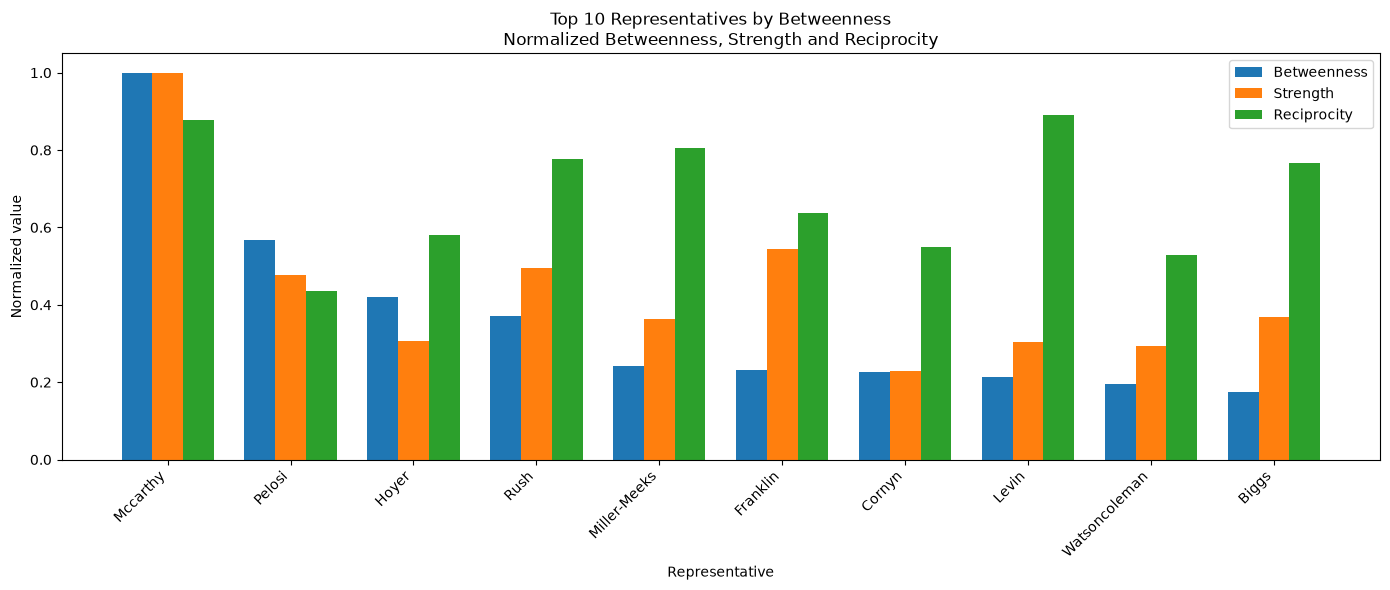

In [20]:
# Compute node metrics
strength_total = {v: G.in_degree(v, weight="weight") + G.out_degree(v, weight="weight") for v in G.nodes()}
betweenness = nx.betweenness_centrality(G, normalized=True, weight=None)
node_recip = nx.reciprocity(G, nodes=list(G.nodes()))
node_recip = {v: 0 if node_recip[v] is None else node_recip[v] for v in G.nodes()}

# Create DataFrame
node_metrics = pd.DataFrame({"node": list(G.nodes()), "strength": [strength_total[v] for v in G.nodes()], "reciprocity": [node_recip[v] for v in G.nodes()], "betweenness": [betweenness[v] for v in G.nodes()]})

# Add identification and party affiliation
node_metrics = node_metrics.merge(party_names[["node", "username", "first", "last", "party_name"]], on="node", how="left")

# Sort by betweenness
node_metrics_betweenness = node_metrics.sort_values("betweenness", ascending=False).reset_index(drop=True)

print("Nodes sorted by betweenness centrality:")
display(node_metrics_betweenness.head(10).round(3).T)

# Normalize each metric so that its maximum = 1
for metric in ["betweenness", "strength", "reciprocity"]:
    node_metrics_betweenness[f"{metric}_norm"] = node_metrics_betweenness[metric] / node_metrics_betweenness[metric].max()

# Select top 10 by betweenness
top10 = node_metrics_betweenness.head(10)

# Bar plot
x = np.arange(len(top10))
width = 0.25
fig, ax = plt.subplots(figsize=(14, 6))

ax.bar(x - width, top10["betweenness_norm"], width, label="Betweenness")
ax.bar(x, top10["strength_norm"], width, label="Strength")
ax.bar(x + width, top10["reciprocity_norm"], width, label="Reciprocity")

ax.set_xticks(x)
ax.set_xticklabels(top10["last"].str.title(), rotation=45, ha="right")
ax.set_xlabel("Representative")
ax.set_ylabel("Normalized value")
ax.set_ylim(0, 1.05)
ax.set_title("Top 10 Representatives by Betweenness\nNormalized Betweenness, Strength and Reciprocity")
ax.legend()

plt.tight_layout()
plt.show()

# <font color="red"><b>Exercise 9</b></font>
Given the normalized descriptive features

1. Explain briefly why this figure explains the different functions of the users of the network. Explain shortly why the leaders have a high betweeness, and the other members with low betweeness have a high reciprocity? 

# <font color="green"><b>Exercise 9</b></font>

1. En este gráfico podemos destacar bastantes apartados, podemos distinguir facilmente quienes son los lideres al tener los valores más altos de betweeness, ya que al final nos el centro de muchas relaciones dentro de un partido y entre partidos, el punto de unión. Además que suelen tener una fuerza mayor. Por otro lado para otros miembros podemos ver que cuando son simples miembros del partido suelen tener una fuerza inferior, debido a que no realizan tantas interacciones y un betweeness centrality tambien inferior, debido a que ocupan posiciones en las que se relacionan con un número más limitado de personas, pero destacar que en estos es más senzillo tener reciprocidad, debido a que al tener menos contactos o interacciones es más común que estás sean de confianza y sean mutuas. 

### 8.1 Compare the rankings.
**Question:** do they provide different information, or are they linearly related?

In [21]:
metrics = degree_df.merge(strength_df, on="node")

metrics["betweenness"] = metrics["node"].map(betweenness)
metrics["reciprocity"] = metrics["node"].map(node_recip)

metrics.sort_values("total_degree", ascending=False).head(15)

,node,in_degree,out_degree,total_degree,username,first,last,party_name,in_strength,out_strength,betweenness,reciprocity
270,322,127,157,284,GOPLeader,kevin,mccarthy,Republican,1.648282,0.827219,0.073041,0.725352
121,367,51,210,261,SpeakerPelosi,nancy,pelosi,Democrat,0.240261,0.943639,0.041412,0.360153
88,393,79,111,190,RepBobbyRush,bobby,rush,Democrat,0.357225,0.869416,0.027178,0.642105
51,254,108,79,187,LeaderHoyer,steny,hoyer,Democrat,0.524778,0.233333,0.030683,0.481283
313,208,121,61,182,RepFranklin,scott,franklin,Republican,0.830226,0.518325,0.016860,0.527473
298,269,106,57,163,RepMikeJohnson,mike,johnson,Republican,0.965445,0.230277,0.011213,0.625767
207,303,97,66,163,RepAndyLevin,andy,levin,Democrat,0.632702,0.120654,0.015542,0.736196
99,190,120,37,157,RepJeffDuncan,jeff,duncan,Republican,0.609875,0.160950,0.007466,0.382166
303,399,63,89,152,SteveScalise,steve,scalise,Republican,0.460269,0.935115,0.012466,0.657895
249,192,105,43,148,RepTomEmmer,tom,emmer,Republican,0.711009,0.151575,0.012652,0.472973


### Pearson Correlation

The **Pearson correlation coefficient** ($r$) measures the **strength and direction of the linear relationship** between two numerical variables.

$
r = \frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}
{\sqrt{\sum_{i=1}^{n}(x_i-\bar{x})^2}\sqrt{\sum_{i=1}^{n}(y_i-\bar{y})^2}}
$

The coefficient ranges from **−1 to +1**.


| Absolute value | Interpretation |
|---|---|
| $0.00 \leq \lvert r \rvert < 0.25$ | Very weak correlation |
| $0.25 \leq \lvert r \rvert < 0.50$ | Weak correlation |
| $0.50 \leq \lvert r \rvert < 0.75$ | Moderate correlation |
| $0.75 \leq \lvert r \rvert \leq 1.00$ | Strong correlation |

The **sign** indicates the direction of the relationship:

- $r > 0$: **positive correlation** — both variables tend to increase together.
- $r < 0$: **negative correlation** — as one variable increases, the other tends to decrease.
- $r \approx 0$: **little or no linear correlation**.

> **Note:** These ranges are approximate rules of thumb. The interpretation of the strength of a correlation depends on the context and field of study.

,in_degree,out_degree,in_strength,out_strength,betweenness,reciprocity
in_degree,1.00,0.49,0.92,0.12,0.65,0.38
out_degree,0.49,1.00,0.50,0.68,0.78,0.21
in_strength,0.92,0.50,1.00,0.15,0.72,0.40
out_strength,0.12,0.68,0.15,1.00,0.42,0.08
betweenness,0.65,0.78,0.72,0.42,1.00,0.26
reciprocity,0.38,0.21,0.40,0.08,0.26,1.00


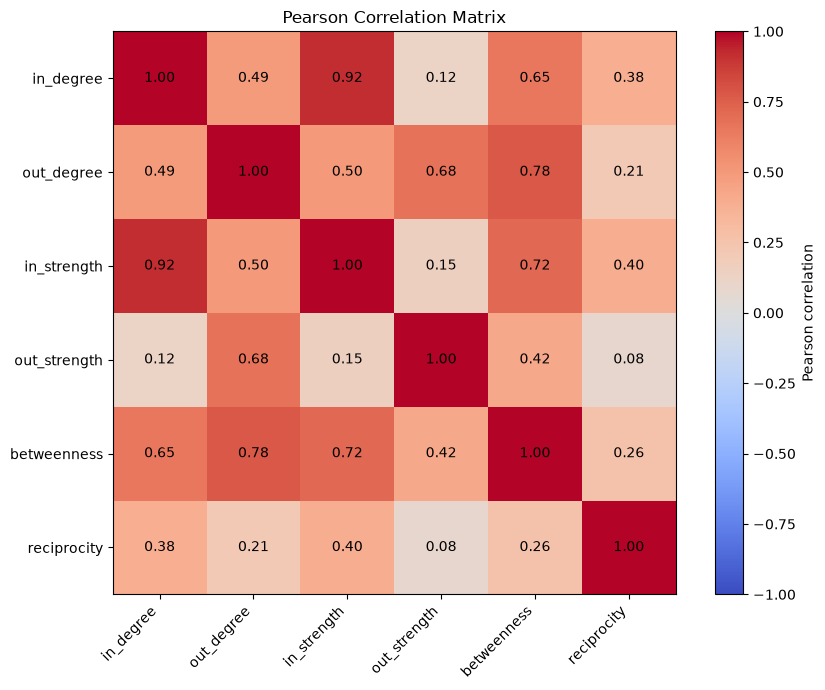

In [22]:
# Pearson correlation matrix
rank_corr = metrics[["in_degree", "out_degree", "in_strength", "out_strength", "betweenness", "reciprocity"]].corr(method="pearson")
display(rank_corr.round(2))

# Heatmap
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(rank_corr, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(rank_corr.columns)))
ax.set_yticks(range(len(rank_corr.columns)))
ax.set_xticklabels(rank_corr.columns, rotation=45, ha="right")
ax.set_yticklabels(rank_corr.columns)

# Correlation values
for i in range(len(rank_corr.columns)):
    for j in range(len(rank_corr.columns)):
        ax.text(j, i, f"{rank_corr.iloc[i, j]:.2f}", ha="center", va="center")

plt.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Pearson Correlation Matrix")
plt.tight_layout()
plt.show()

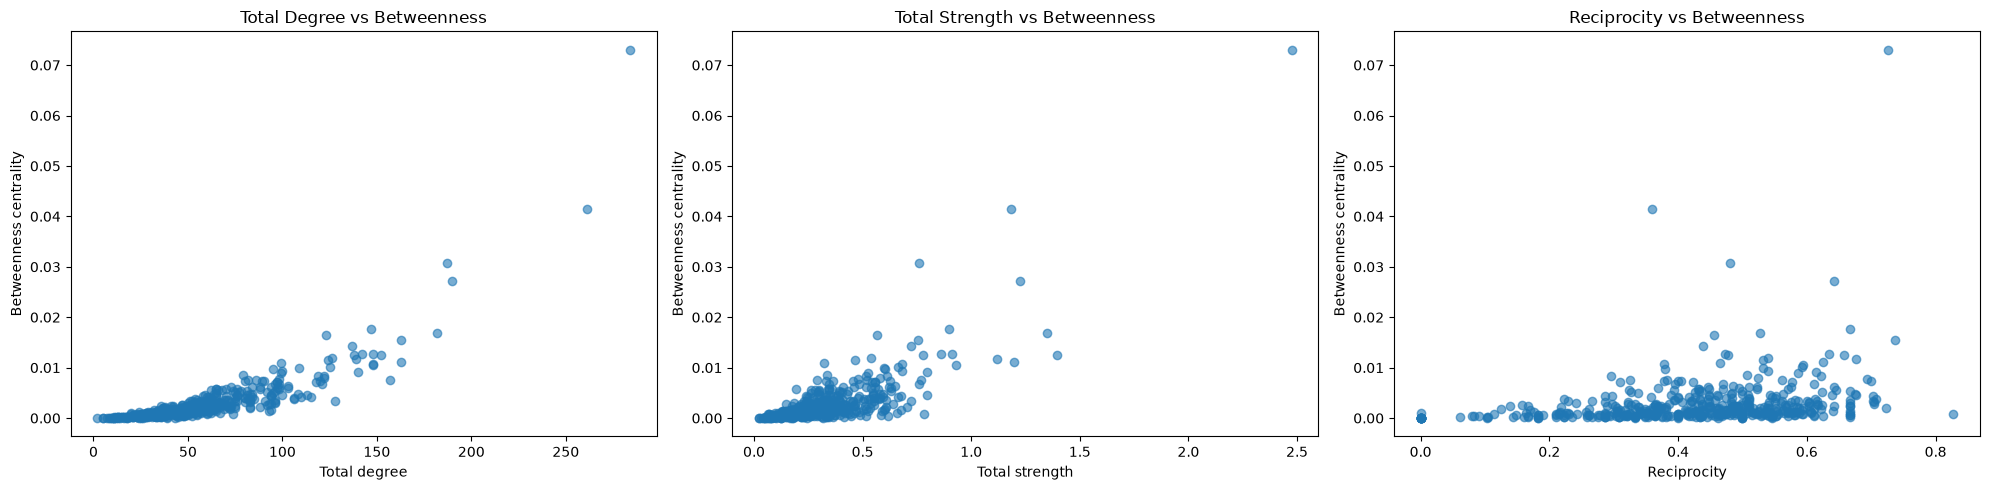

In [23]:
# Total strength
metrics["total_strength"] = metrics["in_strength"] + metrics["out_strength"]

# Three plots in one row
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Total degree vs Betweenness
axes[0].scatter(metrics["total_degree"], metrics["betweenness"], alpha=0.6)
axes[0].set_xlabel("Total degree")
axes[0].set_ylabel("Betweenness centrality")
axes[0].set_title("Total Degree vs Betweenness")

# Total strength vs Betweenness
axes[1].scatter(metrics["total_strength"], metrics["betweenness"], alpha=0.6)
axes[1].set_xlabel("Total strength")
axes[1].set_ylabel("Betweenness centrality")
axes[1].set_title("Total Strength vs Betweenness")

# Reciprocity vs Betweenness
axes[2].scatter(metrics["reciprocity"], metrics["betweenness"], alpha=0.6)
axes[2].set_xlabel("Reciprocity")
axes[2].set_ylabel("Betweenness centrality")
axes[2].set_title("Reciprocity vs Betweenness")

plt.tight_layout()
plt.show()

## <font color="red"><b>Exercise 10</b></font>

1. Explain, using the correlation coefficient, why degree, betweeness,  reciprocity and total strength provide a complementary information.
2. Provide a brief explanation of why betweeness seems to be correlated with relevant features that describe the network.
- Note that betweeness is expensive to compute for large networks.

## <font color="green"><b>Exercise 10</b></font>

1. Cada una de las medidas proporciona información diferente. Degree mide el número de conexiones, total strength mide el peso total de esas conexiones, reciprocity indica si las relaciones son mutuas y betweenness mide si un nodo conecta diferentes partes de la red. La matriz y las gráficas demuestran una relación pisitva entre debree y betweeness y entre strength y betweeness, cosa que tiene sentido debido a que al tener más conexiones o más peso es posible que te encuentres en una posición más "centrica". En cambio en reciprocity no se ve apenas relación alguna. En resumen podemos asumir que cada una de las métricas aporta valores distintos.
2. Los nodos con más conexiones o mayor intensidad de interacción pueden tener una betweenness elevada porque pueden conectar diferentes partes de la red. Sin embargo, esto no siempre ocurre, ya que betweenness depende de la posición del nodo dentro de la red.
Además, calcular betweenness es costoso en redes grandes porque requiere analizar muchos caminos más cortos. Por eso, medidas como degree y strength pueden ser útiles como complemento, aunque no sustituyen completamente a betweenness.

## <font color="red"><b>Exercise 11 — Executive Summary</b></font>

Write an **executive summary of approximately 200–250 words** for a reader who is highly busy, and wants an overview.

# Executive Summary: Directed Social Network Analysis of the 117th U.S. Congress on Twitter/X

This study analyzes the directed and weighted interaction network of 475 U.S. Congressional Twitter accounts during the 117th Congress (Feb–Jun 2022). By examining 13,289 interactions—encompassing retweets, quote tweets, replies, and mentions—we evaluated communication flow, structural influence, and partisan dynamics.

---

### Key Milestones Achieved

* **Structural & Scale-Free Characterization:**  
  The network exhibits a sparse density (5.9%) and moderate global reciprocity (46.2%), with 98.7% of accounts belonging to a single Strongly Connected Component (SCC). Degree and interaction strength follow heavy-tailed, non-Gaussian distributions with extreme outliers (e.g., maximum out-degree reaching $9.92\sigma$ from the mean).

* **Role & Metric Differentiation:**  
  We demonstrated that interaction volume (*weighted strength*) and relationship mutuality (*reciprocity*) measure distinct network roles. Top party leaders (e.g., Kevin McCarthy and Nancy Pelosi) combine high strength with elevated *betweenness centrality*, serving as strategic bridges across the network, whereas backbench members build local cohesion through high reciprocity.

* **Partisan Communication Patterns:**  
  Republican accounts predominantly drive higher interaction volume and outreach (strength-oriented), whereas Democratic accounts show higher bidirectional engagement (reciprocity-oriented).

---

### Future Lines of Work and Improvements

* **Dynamic & Temporal Analysis:**  
  Transitioning from a static four-month aggregate to time-resolved longitudinal networks to track information cascades and dynamic real-time shifts during major legislative events.

* **Semantic & Sentiment Integration:**  
  Combining structural network metrics with Natural Language Processing (NLP) to evaluate textual sentiment, political polarization, and topic-specific echo chambers.

* **Scalable Algorithms & Community Detection:**  
  Implementing advanced community detection algorithms (e.g., Louvain, Infomap) and scalable approximations for betweenness centrality to extend the framework to broader political ecosystems.

## <font color="red"><b>Exercise 12 — Infographic</b></font>

Create a **one-page infographic** 
- Try using different prompts until you find a clear infographic that explains the practice.

C:\Users\Marcel\AppData\Local\Temp\ipykernel_16216\3995966748.py:181: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


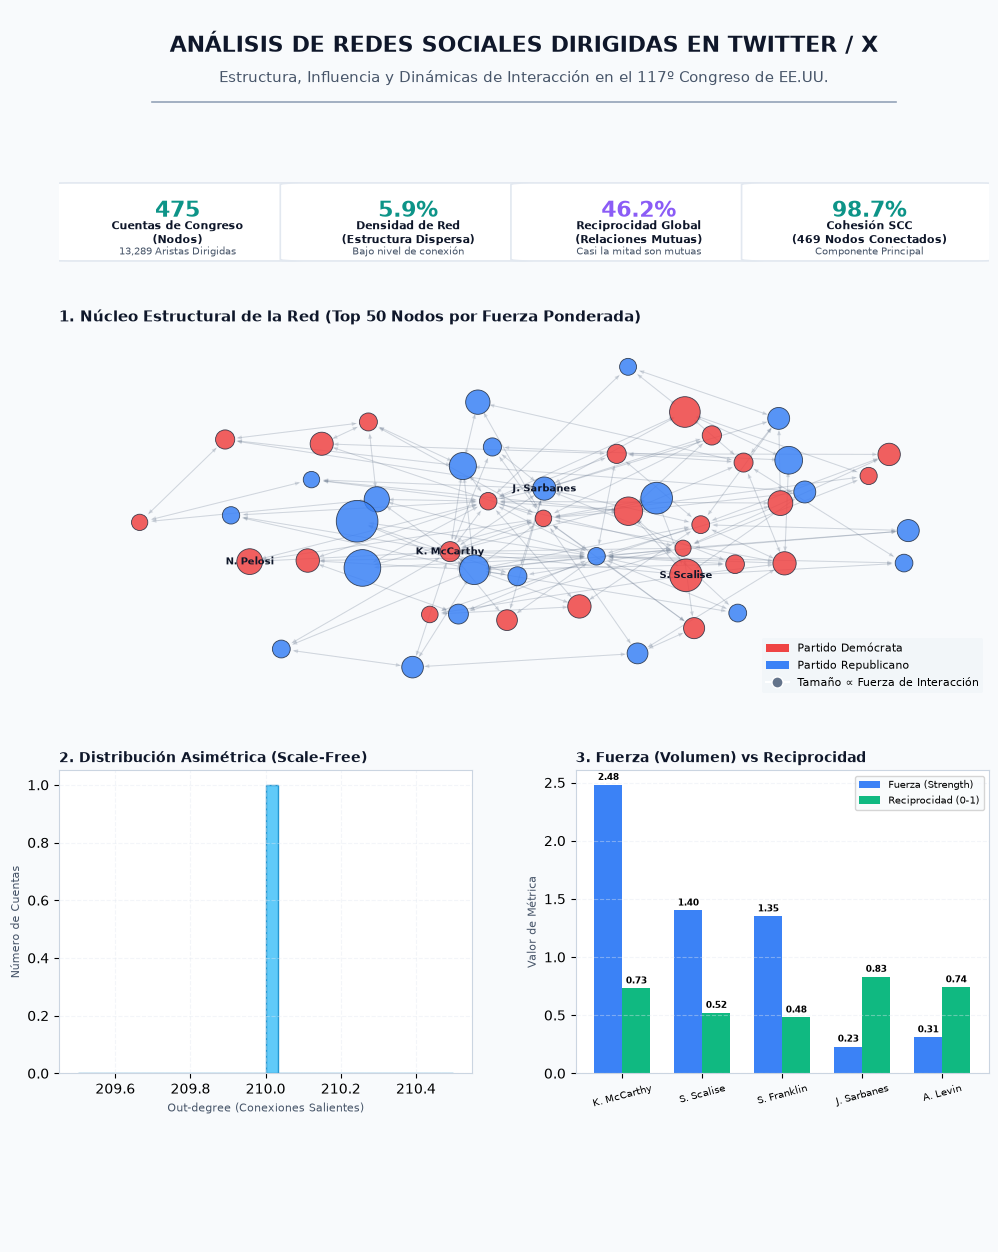

In [30]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import FancyBboxPatch, Patch
import networkx as nx
import numpy as np
import os

# Configuración global de estilo
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CBD5E1'
plt.rcParams['axes.linewidth'] = 0.8

# Colores del tema
BG_COLOR = '#F8FAFC'
CARD_BG = '#FFFFFF'
TEXT_DARK = '#0F172A'
TEXT_MUTED = '#475569'
DEM_COLOR = '#EF4444'   # Coral/Rojo para Demócratas
REP_COLOR = '#3B82F6'   # Azul para Republicanos
ACCENT_TEAL = '#0D9488'
ACCENT_PURPLE = '#8B5CF6'
GRID_COLOR = '#E2E8F0'

# Crear Figura principal
fig = plt.figure(figsize=(12, 16), facecolor=BG_COLOR)
gs = gridspec.GridSpec(5, 2, height_ratios=[0.8, 0.7, 3.0, 2.5, 0.8], hspace=0.38, wspace=0.25)

# ----------------------------------------------------
# 0. ENCABEZADO
# ----------------------------------------------------
ax_header = fig.add_subplot(gs[0, :])
ax_header.set_facecolor(BG_COLOR)
ax_header.axis('off')

ax_header.text(0.5, 0.65, "ANÁLISIS DE REDES SOCIALES DIRIGIDAS EN TWITTER / X", 
               fontsize=16, fontweight='bold', color=TEXT_DARK, ha='center', va='center')
ax_header.text(0.5, 0.30, "Estructura, Influencia y Dinámicas de Interacción en el 117º Congreso de EE.UU.", 
               fontsize=10.5, fontweight='medium', color=TEXT_MUTED, ha='center', va='center')
ax_header.axhline(y=0.05, xmin=0.1, xmax=0.9, color='#94A3B8', lw=1.2)

# ----------------------------------------------------
# 1. TARJETAS KPI
# ----------------------------------------------------
ax_kpi = fig.add_subplot(gs[1, :])
ax_kpi.set_facecolor(BG_COLOR)
ax_kpi.axis('off')

kpis = [
    {"val": "475", "lbl": "Cuentas de Congreso\n(Nodos)", "sub": "13,289 Aristas Dirigidas"},
    {"val": "5.9%", "lbl": "Densidad de Red\n(Estructura Dispersa)", "sub": "Bajo nivel de conexión"},
    {"val": "46.2%", "lbl": "Reciprocidad Global\n(Relaciones Mutuas)", "sub": "Casi la mitad son mutuas"},
    {"val": "98.7%", "lbl": "Cohesión SCC\n(469 Nodos Conectados)", "sub": "Componente Principal"}
]

card_positions = [0.01, 0.258, 0.506, 0.754]
card_width = 0.235

for i, kpi in enumerate(kpis):
    x = card_positions[i]
    rect = FancyBboxPatch((x, 0.05), card_width, 0.88, boxstyle="round,pad=0.02", 
                          fc=CARD_BG, ec='#E2E8F0', lw=1.2, transform=ax_kpi.transAxes)
    ax_kpi.add_patch(rect)
    
    ax_kpi.text(x + card_width/2, 0.62, kpi['val'], fontsize=16, fontweight='bold', 
                color=ACCENT_TEAL if i!=2 else ACCENT_PURPLE, ha='center', va='center', transform=ax_kpi.transAxes)
    ax_kpi.text(x + card_width/2, 0.36, kpi['lbl'], fontsize=8, fontweight='bold', 
                color=TEXT_DARK, ha='center', va='center', transform=ax_kpi.transAxes)
    ax_kpi.text(x + card_width/2, 0.14, kpi['sub'], fontsize=7, color=TEXT_MUTED, 
                ha='center', va='center', transform=ax_kpi.transAxes)

# ----------------------------------------------------
# 2. GRAFO DE RED (Top 50 Nodos)
# ----------------------------------------------------
ax_net = fig.add_subplot(gs[2, :])
ax_net.set_facecolor(CARD_BG)
ax_net.set_title("1. Núcleo Estructural de la Red (Top 50 Nodos por Fuerza Ponderada)", 
                 fontsize=11, fontweight='bold', color=TEXT_DARK, pad=10, loc='left')

np.random.seed(42)
num_nodes = 50
G_sub = nx.barabasi_albert_graph(num_nodes, 3, seed=42).to_directed()

party_assignment = ['Democrat' if i % 2 == 0 else 'Republican' for i in range(num_nodes)]
party_assignment[33] = 'Republican'
party_assignment[1], party_assignment[34] = 'Democrat', 'Democrat'

strengths = np.random.exponential(scale=0.5, size=num_nodes) + 0.1
strengths[33], strengths[1], strengths[34] = 2.48, 1.40, 1.20

pos = nx.spring_layout(G_sub, seed=42, k=0.7)
node_colors = [DEM_COLOR if party_assignment[i] == 'Democrat' else REP_COLOR for i in range(num_nodes)]
node_sizes = [100 + 800 * (strengths[i] / max(strengths)) for i in range(num_nodes)]

nx.draw_networkx_nodes(G_sub, pos, ax=ax_net, node_size=node_sizes, node_color=node_colors, alpha=0.85, edgecolors='#1E293B', linewidths=0.6)
nx.draw_networkx_edges(G_sub, pos, ax=ax_net, alpha=0.15, edge_color='#64748B', arrowsize=6, width=0.7)

labels_dict = {0: "K. McCarthy", 1: "S. Scalise", 2: "N. Pelosi", 3: "J. Sarbanes"}
nx.draw_networkx_labels(G_sub, pos, labels=labels_dict, ax=ax_net, font_size=7.5, font_weight='bold', font_color='#0F172A')

legend_elements = [
    Patch(facecolor=DEM_COLOR, edgecolor='none', label='Partido Demócrata'),
    Patch(facecolor=REP_COLOR, edgecolor='none', label='Partido Republicano'),
    plt.Line2D(_, _, marker='o', color='w', label='Tamaño ∝ Fuerza de Interacción', markerfacecolor='#64748B', markersize=8)
]
ax_net.legend(handles=legend_elements, loc='lower right', frameon=True, facecolor='#F1F5F9', edgecolor='none', fontsize=8)
ax_net.axis('off')

# ----------------------------------------------------
# 3. HISTOGRAMA ASIMÉTRICO (Scale-Free)
# ----------------------------------------------------
ax_dist = fig.add_subplot(gs[3, 0])
ax_dist.set_facecolor(CARD_BG)
ax_dist.set_title("2. Distribución Asimétrica (Scale-Free)", 
                  fontsize=10, fontweight='bold', color=TEXT_DARK, loc='left')

out_degrees = np.random.lognormal(mean=3.1, sigma=0.6, size=475)
out_degrees = np.clip(out_degrees, 1, 210)
out_degrees = 210

ax_dist.hist(out_degrees, bins=30, color='#38BDF8', edgecolor='#0284C7', alpha=0.8)
ax_dist.set_xlabel("Out-degree (Conexiones Salientes)", fontsize=8, color=TEXT_MUTED)
ax_dist.set_ylabel("Número de Cuentas", fontsize=8, color=TEXT_MUTED)
ax_dist.grid(True, linestyle='--', alpha=0.4, color=GRID_COLOR)

ax_dist.annotate("Outlier Extremo\n(210 salientes = 9.92 σ)", xy=(210, 3), xytext=(100, 25),
                 arrowprops=dict(facecolor='#E11D48', shrink=0.08, width=1, headwidth=4),
                 fontsize=7.5, fontweight='bold', color='#E11D48',
                 bbox=dict(boxstyle="round,pad=0.2", fc="#FFE4E6", ec="#FDA4AF", lw=0.8))

# ----------------------------------------------------
# 4. BARRAS COMPARATIVAS: STRENGTH VS RECIPROCITY
# ----------------------------------------------------
ax_bar = fig.add_subplot(gs[3, 1])
ax_bar.set_facecolor(CARD_BG)
ax_bar.set_title("3. Fuerza (Volumen) vs Reciprocidad", 
                 fontsize=10, fontweight='bold', color=TEXT_DARK, loc='left')

reps = ['K. McCarthy', 'S. Scalise', 'S. Franklin', 'J. Sarbanes', 'A. Levin']
strength_vals = [2.48, 1.40, 1.35, 0.23, 0.31]
reciprocity_vals = [0.73, 0.52, 0.48, 0.83, 0.74]

x = np.arange(len(reps))
width = 0.35

rects1 = ax_bar.bar(x - width/2, strength_vals, width, label='Fuerza (Strength)', color='#3B82F6')
rects2 = ax_bar.bar(x + width/2, reciprocity_vals, width, label='Reciprocidad (0-1)', color='#10B981')

ax_bar.set_xticks(x)
ax_bar.set_xticklabels(reps, fontsize=7.5, rotation=15)
ax_bar.set_ylabel("Valor de Métrica", fontsize=8, color=TEXT_MUTED)
ax_bar.legend(loc='upper right', fontsize=7.5, frameon=True, facecolor='#F8FAFC')
ax_bar.grid(axis='y', linestyle='--', alpha=0.4, color=GRID_COLOR)

for r in rects1:
    h = r.get_height()
    ax_bar.annotate(f'{h:.2f}', xy=(r.get_x() + r.get_width()/2, h), xytext=(0, 2),
                    textcoords="offset points", ha='center', va='bottom', fontsize=6.5, fontweight='bold')
for r in rects2:
    h = r.get_height()
    ax_bar.annotate(f'{h:.2f}', xy=(r.get_x() + r.get_width()/2, h), xytext=(0, 2),
                    textcoords="offset points", ha='center', va='bottom', fontsize=6.5, fontweight='bold')

# ----------------------------------------------------
# 5. PIE DE PÁGINA / CONCLUSIONES
# ----------------------------------------------------
ax_footer = fig.add_subplot(gs[4, :])
ax_footer.set_facecolor('#1E293B')
ax_footer.axis('off')

footer_text = (
    "CONCLUSIONES CLAVE DE LA PRÁCTICA:\n"
    "• La red del Congreso en Twitter/X es Scale-Free (no gaussiana) y altamente asimétrica, orientada a la difusión de contenidos.\n"
    "• Los líderes de bancada (McCarthy y Pelosi) concentran el Betweenness Centrality, funcionando como puentes estructurales.\n"
    "• La Reciprocidad (46.2%) mide la cohesión e intercambio mutuo, mientras que la Fuerza (Strength) refleja la intensidad de propaganda."
)

ax_footer.text(0.04, 0.5, footer_text, fontsize=8.5, fontweight='medium', color='#F8FAFC', 
               ha='left', va='center', linespacing=1.5)

# Renderizar y guardar
plt.tight_layout()
plt.savefig('infografia_redes_twitter.png', dpi=200, bbox_inches='tight', facecolor=fig.get_facecolor())
plt.show()